
---Random Forest Results---

Accuracy: 0.6622%
Precision: 0.6745898885698776
Recall   : 0.6621923937360179
F1 Score : 0.6606780306717472

Confusion Matrix
[[ 58   2   2   5  10   4   2   1   0   8   3]
 [  2  57   1   4   1   3   6   5   8   5   4]
 [  2   1  51   2   0   9  10   3   2   2   3]
 [  0   6   1  96   9   6  12   6   1   5   9]
 [  1   1   1   3  91   5   7   3   3   1  23]
 [  0   1   2   4   7 111   3   2   2   3  10]
 [  0   3   3   5   6  11 103   1   1   2   7]
 [  0  10   2   5   6   7  12  53   4   6   9]
 [  0   7   1   5   4   9   4   3  74   3   9]
 [  2   2   1   5   3   1   5   1   4  74  11]
 [  0   0   2   2   9   5   0   3   3   2 120]]

--- Feature Importance ---


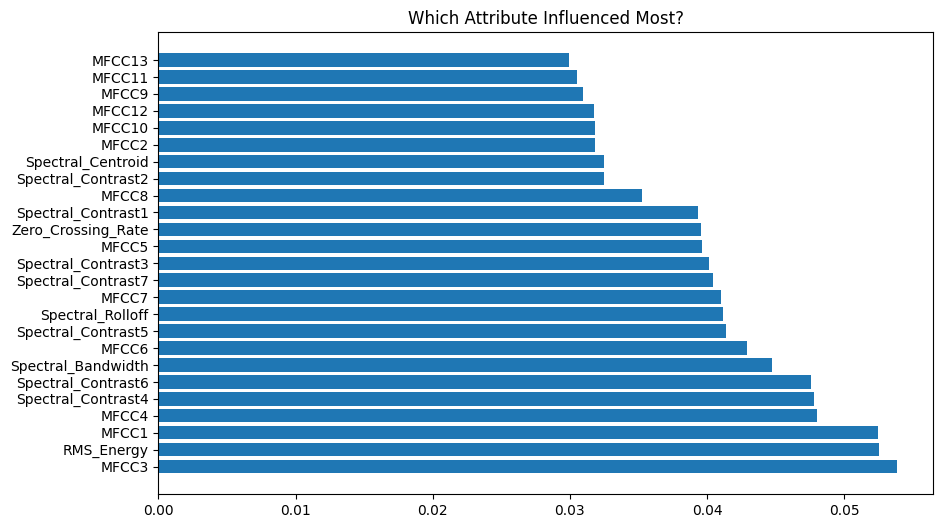

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
# 1. Prepare Data
data=pd.read_csv(r"C:\course\sem 4\ml Project\Music Dataset.csv")
X = data.drop("Instrument",axis=1)
y = data["Instrument"]

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Implement Random Forest
# n_estimators=100 means we are building 100 individual trees
rf_clf = RandomForestClassifier(n_estimators=500, criterion='entropy', random_state=42,max_features="sqrt",n_jobs=-1)
rf_clf.fit(X_train, y_train)


# 4. Predict and Evaluate
y_tpred = rf_clf.predict(X_test)

precision = precision_score(y_test, y_tpred, average="weighted")
recall = recall_score(y_test, y_tpred, average="weighted")
f1 = f1_score(y_test, y_tpred, average="weighted")
print(f"\n---Random Forest Results---\n")

print(f"Accuracy: {accuracy_score(y_test, y_tpred):.4f}%")
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_tpred))

# 5. Feature Importance
# One of the best parts of Random Forest is seeing which features matter most!
importances = rf_clf.feature_importances_
feature_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_df = feature_df.sort_values(by='Importance', ascending=False)
print("\n--- Feature Importance ---")
plt.figure(figsize=(10, 6))
plt.barh(feature_df["Feature"],feature_df["Importance"])
plt.title('Which Attribute Influenced Most?')
plt.show()